# Plot Backazimuth Results

Multi-event visualization of **backazimuth** and cross-correlation results from the BRS pipeline. This notebook:

- Loads `./results/backazimuth_results.csv` from **04_brs_combine_results.py**
- Compares estimated backazimuth (velocity/acceleration, max and mid CC methods, tangent estimates) to **theoretical** values
- Plots cross-correlation scores (zero-lag vs. lag-corrected) and flags **polarity-flipped** events
- Summarizes deviations with histograms, KDE densities, and an event **map** (distance vs. backazimuth)
- Saves summary figures under `./results/` (e.g. `backazimuth_comparison_all_methods.png`, `backazimuth_results_summary.png`)

Set `cc_threshold` and `path_to_data` in the configuration cell below. Run after batch or notebook analysis (**03_brs_analysis**) and the combine step.

### Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats


def event_x_positions(valid_base, subset, offset=0.0):
    """Map DataFrame row labels to x-axis positions for bar/errorbar plots."""
    pos = {idx: i for i, idx in enumerate(valid_base.index)}
    return np.array([pos[idx] for idx in subset.index], dtype=float) + offset


### Configurations

In [3]:
# CC threshold
cc_threshold = 0.4

# Specify path to backazimuth results
path_to_data = "./output/backazimuth_results.csv"

# Path to figures
save_figures = True
path_to_figures = "./figures/"


## Load Data

In [4]:
# Load backazimuth results
df_baz = pd.read_csv(path_to_data)

print(f"Loaded {len(df_baz)} events")
print(f"\nColumns: {list(df_baz.columns)}")
df_baz.head()

Loaded 19 events

Columns: ['event', 'date', 'magnitude', 'epicentral_distance_km', 'depth_km', 'baz_vel_max_peak', 'baz_vel_max_uncertainty', 'baz_vel_max_count', 'baz_vel_mid_peak', 'baz_vel_mid_uncertainty', 'baz_vel_mid_count', 'baz_vel_theoretical', 'baz_acc_max_peak', 'baz_acc_max_uncertainty', 'baz_acc_max_count', 'baz_acc_mid_peak', 'baz_acc_mid_uncertainty', 'baz_acc_mid_count', 'baz_acc_theoretical', 'tangent_vel_mid', 'tangent_vel_mid_uncertainty', 'tangent_vel_max', 'tangent_vel_max_uncertainty', 'tangent_acc_mid', 'tangent_acc_mid_uncertainty', 'tangent_acc_max', 'tangent_acc_max_uncertainty', 'cc_lag_samples', 'cc_max', 'cc_zero_lag_before', 'cc_zero_lag_after', 'polarity_flip']


,event,date,magnitude,epicentral_distance_km,depth_km,baz_vel_max_peak,baz_vel_max_uncertainty,baz_vel_max_count,baz_vel_mid_peak,baz_vel_mid_uncertainty,...,tangent_vel_max_uncertainty,tangent_acc_mid,tangent_acc_mid_uncertainty,tangent_acc_max,tangent_acc_max_uncertainty,cc_lag_samples,cc_max,cc_zero_lag_before,cc_zero_lag_after,polarity_flip
0,event_20190706,2019-07-06 03:19:53,7.1,2559.26,8.00,9.0,27.0,53.0,2.0,21.0,...,11.0,362.0,11.0,362.0,11.0,6,0.56,0.49,0.56,0
1,event_20200623,2020-06-23 15:29:04,7.4,1710.74,20.00,90.0,39.0,69.0,142.0,39.0,...,24.0,149.0,24.0,149.0,24.0,29,0.30,0.17,0.30,0
2,event_20200722,2020-07-22 06:12:44,7.8,5894.82,28.00,390.0,43.0,126.0,357.0,24.0,...,23.0,355.0,23.0,355.0,23.0,6,0.74,0.71,0.74,0
3,event_20201019,2020-10-19 20:54:38,7.6,5963.15,28.37,30.0,37.0,84.0,348.0,10.0,...,9.0,349.0,9.0,349.0,9.0,6,0.77,0.74,0.77,0
4,event_20210304,2021-03-04 19:28:33,8.1,11324.54,28.93,250.0,58.0,127.0,222.0,38.0,...,37.0,222.0,37.0,222.0,37.0,-10,0.83,0.79,0.83,1


In [5]:
rename_map = {
    "event_20230206_01": "event_20230206a",
    "event_20230206_02": "event_20230206b",
}
df_baz["event"] = df_baz["event"].replace(rename_map)


## Cross-Correlation Comparison

Compare cross-correlation with and without lag correction.

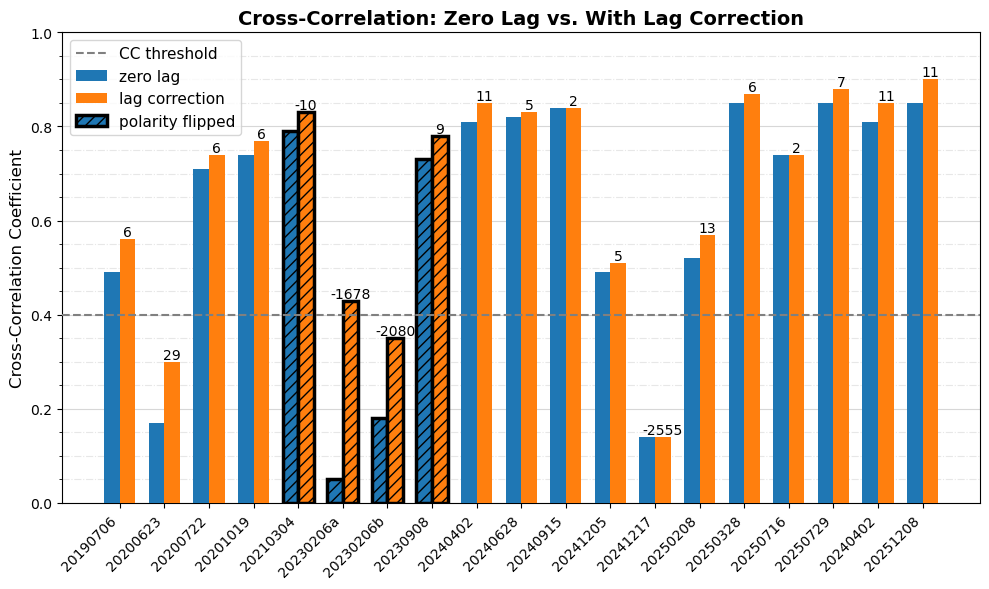


Statistics:
  Mean CC (zero lag): 0.609 ± 0.278
  Mean CC (with lag): 0.671 ± 0.228
  Improvement: 0.061 ± 0.088
  Events with polarity flip: 4


In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

# Filter out NaN values
valid_data = df_baz.dropna(subset=['cc_zero_lag_before', 'cc_zero_lag_after', 'cc_lag_samples', 'polarity_flip'])

x = np.arange(len(valid_data))
width = 0.35


# Plot CC threshold
ax.axhline(y=cc_threshold, color='gray', linestyle='--', linewidth=1.5, label='CC threshold', zorder=10)

# Plot all bars
bars1 = ax.bar(x - width/2, valid_data['cc_zero_lag_before'], width, zorder=4,
            label='zero lag', alpha=1, color='tab:blue', edgecolor='none')
bars2 = ax.bar(x + width/2, valid_data['cc_zero_lag_after'], width, zorder=4,
            label='lag correction', alpha=1, color='tab:orange', edgecolor='none')

# Mark polarity-flipped events with distinctive edge color and hatch pattern
polarity_flipped_mask = valid_data['polarity_flip'] == 1
if polarity_flipped_mask.any():
    x_flipped = x[polarity_flipped_mask]
    
    # Overlay bars for polarity-flipped events with edge color and hatch
    bars1_flipped = ax.bar(x_flipped - width/2, valid_data.loc[polarity_flipped_mask, 'cc_zero_lag_before'], 
                           width, alpha=1, color='tab:blue', edgecolor='k', linewidth=2.5, zorder=4,
                           hatch='///', label='polarity flipped')
    bars2_flipped = ax.bar(x_flipped + width/2, valid_data.loc[polarity_flipped_mask, 'cc_zero_lag_after'], 
                           width, alpha=1, color='tab:orange', edgecolor='k', linewidth=2.5, zorder=4,
                           hatch='///')

# add text in bar with lag samples
for i, bar in enumerate(bars2):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), 
            f"{valid_data['cc_lag_samples'].iloc[i]:.0f}",
            ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Cross-Correlation Coefficient', fontsize=12)
ax.set_title('Cross-Correlation: Zero Lag vs. With Lag Correction', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(valid_data['event'].str.replace('event_', '').values, rotation=45, ha='right')
ax.legend(fontsize=11)
ax.get_yaxis().set_minor_locator(mpl.ticker.AutoMinorLocator())
ax.grid(which='major', alpha=0.5, axis='y', zorder=0)
ax.grid(which='minor', alpha=0.3, axis='y', zorder=0, ls="-.")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/cross_correlation_comparison.png", bbox_inches='tight', dpi=150)


# Print statistics
print(f"\nStatistics:")
print(f"  Mean CC (zero lag): {valid_data['cc_zero_lag_before'].mean():.3f} ± {valid_data['cc_zero_lag_before'].std():.3f}")
print(f"  Mean CC (with lag): {valid_data['cc_zero_lag_after'].mean():.3f} ± {valid_data['cc_zero_lag_after'].std():.3f}")
print(f"  Improvement: {(valid_data['cc_zero_lag_after'] - valid_data['cc_zero_lag_before']).mean():.3f} ± {(valid_data['cc_zero_lag_after'] - valid_data['cc_zero_lag_before']).std():.3f}")
if polarity_flipped_mask.any():
    print(f"  Events with polarity flip: {polarity_flipped_mask.sum()}")

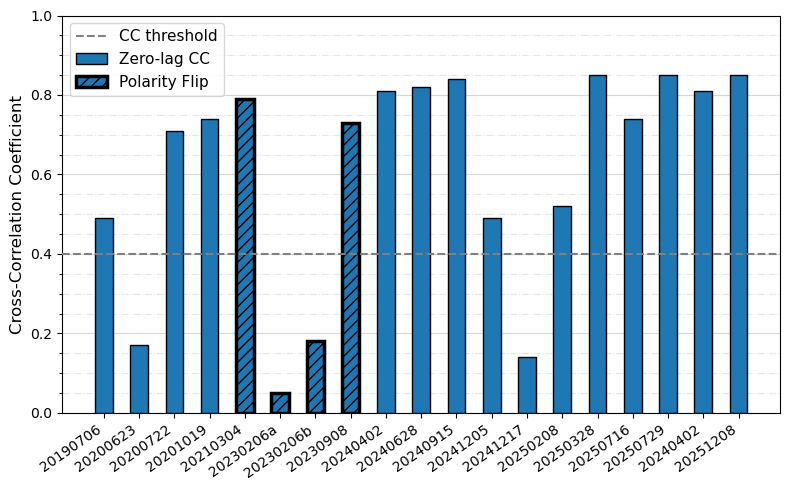


Statistics:
  Mean CC (zero lag): 0.609 ± 0.278
  Mean CC (with lag): 0.671 ± 0.228
  Improvement: 0.061 ± 0.088
  Events with polarity flip: 4


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

# Filter out NaN values
valid_data = df_baz.dropna(subset=['cc_zero_lag_before', 'cc_zero_lag_after', 'cc_lag_samples', 'polarity_flip'])

x = np.arange(len(valid_data))
width = 0.5


# Plot CC threshold
ax.axhline(y=cc_threshold, color='gray', linestyle='--', linewidth=1.5, label='CC threshold', zorder=10)

# Plot all bars
bars1 = ax.bar(x, valid_data['cc_zero_lag_before'], width, zorder=4,
            label='Zero-lag CC', alpha=1, color='tab:blue', edgecolor='k')
# bars2 = ax.bar(x + width/2, valid_data['cc_zero_lag_after'], width, zorder=4,
#             label='lag correction', alpha=1, color='tab:orange', edgecolor='none')

# Mark polarity-flipped events with distinctive edge color and hatch pattern
polarity_flipped_mask = valid_data['polarity_flip'] == 1
if polarity_flipped_mask.any():
    x_flipped = x[polarity_flipped_mask]
    
    # Overlay bars for polarity-flipped events with edge color and hatch
    bars1_flipped = ax.bar(x_flipped, valid_data.loc[polarity_flipped_mask, 'cc_zero_lag_before'], 
                           width, alpha=1, color='tab:blue', edgecolor='k', linewidth=2.5, zorder=4,
                           hatch='///', label='Polarity Flip')
    # bars2_flipped = ax.bar(x_flipped + width/2, valid_data.loc[polarity_flipped_mask, 'cc_zero_lag_after'], 
    #                        width, alpha=1, color='tab:orange', edgecolor='k', linewidth=2.5, zorder=4,
    #                        hatch='///')

# add text in bar with lag samples
# for i, bar in enumerate(bars2):
#     ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), 
#             f"{valid_data['cc_lag_samples'].iloc[i]:.0f}",
#             ha='center', va='bottom', fontsize=10)

ax.set_ylabel('Cross-Correlation Coefficient', fontsize=12)
# ax.set_title('Cross-Correlation: Zero Lag vs. With Lag Correction', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(valid_data['event'].str.replace('event_', '').values, rotation=35, ha='right')
ax.legend(fontsize=11)
ax.get_yaxis().set_minor_locator(mpl.ticker.AutoMinorLocator())
ax.grid(which='major', alpha=0.5, axis='y', zorder=0)
ax.grid(which='minor', alpha=0.3, axis='y', zorder=0, ls="-.")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/cross_correlation_comparison.png", bbox_inches='tight', dpi=150)


# Print statistics
print(f"\nStatistics:")
print(f"  Mean CC (zero lag): {valid_data['cc_zero_lag_before'].mean():.3f} ± {valid_data['cc_zero_lag_before'].std():.3f}")
print(f"  Mean CC (with lag): {valid_data['cc_zero_lag_after'].mean():.3f} ± {valid_data['cc_zero_lag_after'].std():.3f}")
print(f"  Improvement: {(valid_data['cc_zero_lag_after'] - valid_data['cc_zero_lag_before']).mean():.3f} ± {(valid_data['cc_zero_lag_after'] - valid_data['cc_zero_lag_before']).std():.3f}")
if polarity_flipped_mask.any():
    print(f"  Events with polarity flip: {polarity_flipped_mask.sum()}")

In [8]:
# filter by CC value
df_baz = df_baz[df_baz['cc_zero_lag_before'].abs() > cc_threshold]

## Backazimuth Comparison

Compare estimated backazimuth (with uncertainty) versus theoretical value.

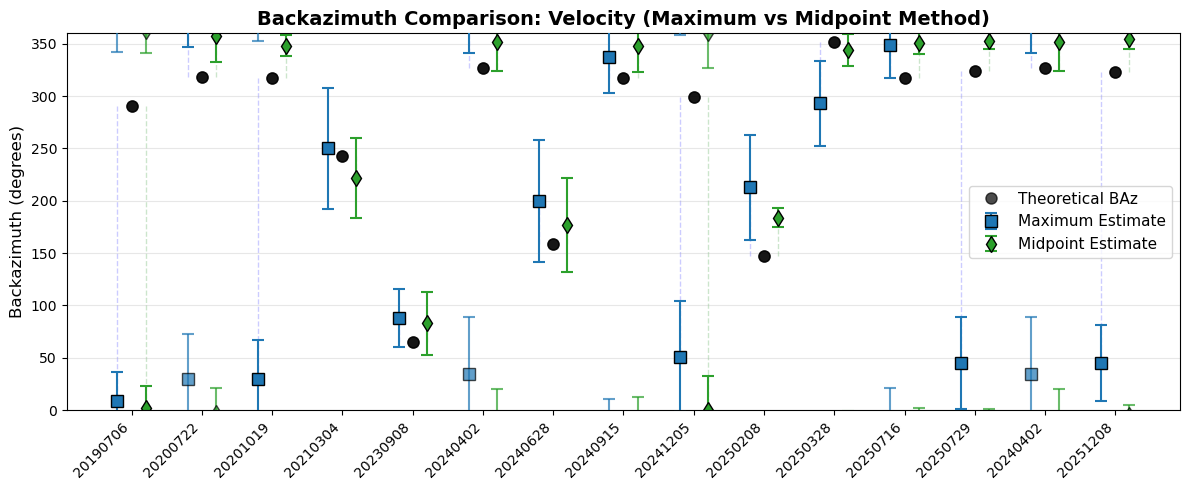

In [9]:
# Velocity - Combined Max and Mid methods
fig, ax = plt.subplots(figsize=(12, 5))

# Get events that have theoretical values
valid_base = df_baz.dropna(subset=['baz_vel_theoretical'])
x_base = np.arange(len(valid_base))
theoretical = valid_base['baz_vel_theoretical'].values
width = 0.2  # Shift width for positioning

# Plot theoretical values (centered) - twice
ax.errorbar(x_base, theoretical, fmt='o', color='black', markersize=8, 
            label='Theoretical BAz', linewidth=2, zorder=4, alpha=0.7)
ax.errorbar(x_base, theoretical % 360, fmt='o', color='black', markersize=8, 
            linewidth=2, zorder=4, alpha=0.7)

pos = {idx: i for i, idx in enumerate(valid_base.index)}

# Max method
valid_max = valid_base.dropna(subset=['baz_vel_max_peak', 'baz_vel_max_uncertainty'])
if len(valid_max) > 0:
    x_max = event_x_positions(valid_base, valid_max, offset=-width)
    estimated_max = valid_max['baz_vel_max_peak'].values
    uncertainty_max = valid_max['baz_vel_max_uncertainty'].values
    
    # Plot original, +360, and -360
    ax.errorbar(x_max, estimated_max, yerr=uncertainty_max, fmt='s', color='tab:blue', 
                markersize=8, capsize=4, capthick=1.5, alpha=1,
                label='Maximum Estimate', linewidth=1.5, zorder=3, markeredgecolor='k')
    ax.errorbar(x_max, estimated_max + 360, yerr=uncertainty_max, fmt='s', color='tab:blue', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=3, markeredgecolor='k')
    ax.errorbar(x_max, estimated_max - 360, yerr=uncertainty_max, fmt='s', color='tab:blue', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=3, markeredgecolor='k')
    
    # Add difference lines for max
    for i, idx in enumerate(valid_max.index):
        x_pos = pos[idx] - width
        theo_val = valid_base.loc[idx, 'baz_vel_theoretical']
        est_val = estimated_max[i]
        ax.plot([x_pos, x_pos], [theo_val, est_val], 
                'b--', alpha=0.2, linewidth=1, zorder=1)

# Mid method
valid_mid = valid_base.dropna(subset=['baz_vel_mid_peak', 'baz_vel_mid_uncertainty'])
if len(valid_mid) > 0:
    x_mid = event_x_positions(valid_base, valid_mid, offset=width)
    estimated_mid = valid_mid['baz_vel_mid_peak'].values
    uncertainty_mid = valid_mid['baz_vel_mid_uncertainty'].values
    
    # Plot original, +360, and -360
    ax.errorbar(x_mid, estimated_mid, yerr=uncertainty_mid, fmt='d', color='tab:green', 
                markersize=8, capsize=4, capthick=1.5, alpha=1,
                label='Midpoint Estimate', linewidth=1.5, zorder=2, markeredgecolor='k')
    ax.errorbar(x_mid, estimated_mid + 360, yerr=uncertainty_mid, fmt='d', color='tab:green', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=2, markeredgecolor='k')
    ax.errorbar(x_mid, estimated_mid - 360, yerr=uncertainty_mid, fmt='d', color='tab:green', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=2, markeredgecolor='k')
    
    # Add difference lines for mid
    for i, idx in enumerate(valid_mid.index):
        x_pos = pos[idx] + width
        theo_val = valid_base.loc[idx, 'baz_vel_theoretical']
        est_val = estimated_mid[i]
        ax.plot([x_pos, x_pos], [theo_val, est_val], 
                'g--', alpha=0.2, linewidth=1, zorder=1)

# ax.set_xlabel('Event Index', fontsize=12)
ax.set_ylabel('Backazimuth (degrees)', fontsize=12)
ax.set_title('Backazimuth Comparison: Velocity (Maximum vs Midpoint Method)', fontsize=14, fontweight='bold')
ax.set_xticks(x_base)
ax.set_xticklabels(valid_base['event'].str.replace('event_', '').values, rotation=45, ha='right')
ax.set_ylim(0, 360)
ax.legend(fontsize=11, loc=7)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_comparison_velocity.png", bbox_inches='tight', dpi=150)

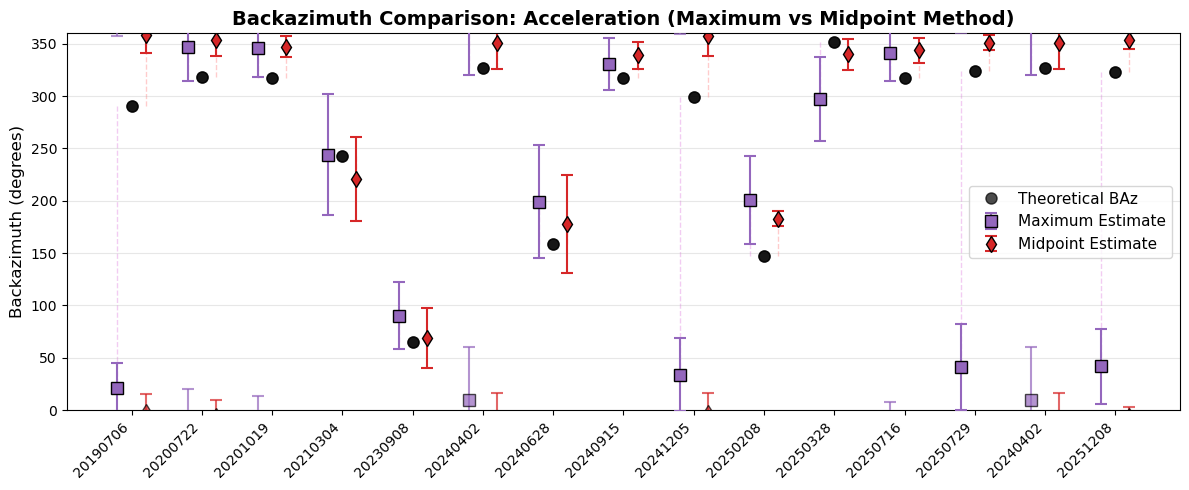

In [10]:
# Acceleration - Combined Max and Mid methods
fig, ax = plt.subplots(figsize=(12, 5))

# Get events that have theoretical values
valid_base = df_baz.dropna(subset=['baz_acc_theoretical'])
x_base = np.arange(len(valid_base))
theoretical = valid_base['baz_acc_theoretical'].values
width = 0.2  # Shift width for positioning

# Plot theoretical values (centered) - twice
ax.errorbar(x_base, theoretical, fmt='o', color='black', markersize=8, 
            label='Theoretical BAz', linewidth=2, zorder=4, alpha=0.7)
ax.errorbar(x_base, theoretical % 360, fmt='o', color='black', markersize=8, 
            linewidth=2, zorder=4, alpha=0.7)

pos = {idx: i for i, idx in enumerate(valid_base.index)}

# Max method
valid_max = valid_base.dropna(subset=['baz_acc_max_peak', 'baz_acc_max_uncertainty'])
if len(valid_max) > 0:
    x_max = event_x_positions(valid_base, valid_max, offset=-width)
    estimated_max = valid_max['baz_acc_max_peak'].values
    uncertainty_max = valid_max['baz_acc_max_uncertainty'].values
    
    # Plot original, +360, and -360
    ax.errorbar(x_max, estimated_max, yerr=uncertainty_max, fmt='s', color='tab:purple', 
                markersize=8, capsize=4, capthick=1.5, alpha=1,
                label='Maximum Estimate', linewidth=1.5, zorder=3, markeredgecolor='k')
    ax.errorbar(x_max, estimated_max + 360, yerr=uncertainty_max, fmt='s', color='tab:purple', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=3, markeredgecolor='k')
    ax.errorbar(x_max, estimated_max - 360, yerr=uncertainty_max, fmt='s', color='tab:purple', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=3, markeredgecolor='k')
    
    # Add difference lines for max
    for i, idx in enumerate(valid_max.index):
        x_pos = pos[idx] - width
        theo_val = valid_base.loc[idx, 'baz_acc_theoretical']
        est_val = estimated_max[i]
        ax.plot([x_pos, x_pos], [theo_val, est_val], 
                'm--', alpha=0.2, linewidth=1, zorder=1)

# Mid method
valid_mid = valid_base.dropna(subset=['baz_acc_mid_peak', 'baz_acc_mid_uncertainty'])
if len(valid_mid) > 0:
    x_mid = event_x_positions(valid_base, valid_mid, offset=width)
    estimated_mid = valid_mid['baz_acc_mid_peak'].values
    uncertainty_mid = valid_mid['baz_acc_mid_uncertainty'].values
    
    # Plot original, +360, and -360
    ax.errorbar(x_mid, estimated_mid, yerr=uncertainty_mid, fmt='d', color='tab:red', 
                markersize=8, capsize=4, capthick=1.5, alpha=1,
                label='Midpoint Estimate', linewidth=1.5, zorder=2, markeredgecolor='k')
    ax.errorbar(x_mid, estimated_mid + 360, yerr=uncertainty_mid, fmt='d', color='tab:red', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=2, markeredgecolor='k')
    ax.errorbar(x_mid, estimated_mid - 360, yerr=uncertainty_mid, fmt='d', color='tab:red', 
                markersize=8, capsize=4, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=2, markeredgecolor='k')
    
    # Add difference lines for mid
    for i, idx in enumerate(valid_mid.index):
        x_pos = pos[idx] + width
        theo_val = valid_base.loc[idx, 'baz_acc_theoretical']
        est_val = estimated_mid[i]
        ax.plot([x_pos, x_pos], [theo_val, est_val], 
                'r--', alpha=0.2, linewidth=1, zorder=1)

# ax.set_xlabel('Event Index', fontsize=12)
ax.set_ylabel('Backazimuth (degrees)', fontsize=12)
ax.set_title('Backazimuth Comparison: Acceleration (Maximum vs Midpoint Method)', fontsize=14, fontweight='bold')
ax.set_xticks(x_base)
ax.set_xticklabels(valid_base['event'].str.replace('event_', '').values, rotation=45, ha='right')
ax.set_ylim(0, 360)
ax.legend(fontsize=11, loc=7)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_comparison_acceleration.png", bbox_inches='tight', dpi=150)

## Combined Backazimuth Comparison

Compare all methods (velocity max/mid, acceleration max/mid, and tangent estimates) versus theoretical values.

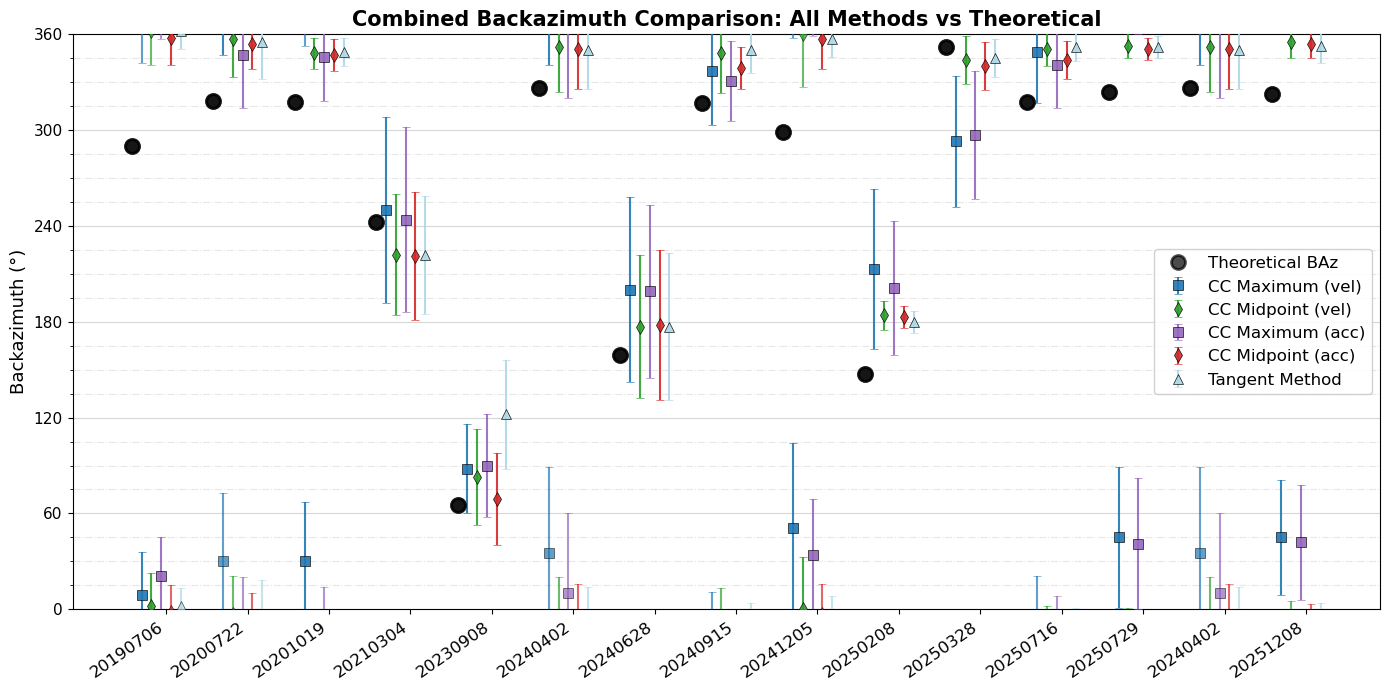

In [11]:
# Combined plot: All methods vs theoretical
fig, ax = plt.subplots(figsize=(14, 7))

# Get events that have theoretical values (use velocity theoretical as base)
valid_base = df_baz.dropna(subset=['baz_vel_theoretical'])
x_base = np.arange(len(valid_base))
theoretical = valid_base['baz_vel_theoretical'].values
width = 0.12  # Shift width for positioning multiple methods

# Plot theoretical values (leftmost position) - twice
x_theoretical = x_base - width * 3.5
ax.errorbar(x_theoretical, theoretical, fmt='o', color='black', markersize=10, 
            label='Theoretical BAz', linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)
ax.errorbar(x_theoretical, theoretical % 360, fmt='o', color='black', markersize=10, 
            linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)

# Velocity Max method
valid_vel_max = valid_base.dropna(subset=['baz_vel_max_peak', 'baz_vel_max_uncertainty'])
if len(valid_vel_max) > 0:
    x_vel_max = x_base[valid_base.index.isin(valid_vel_max.index)] - width * 2.5
    estimated = valid_vel_max['baz_vel_max_peak'].values
    uncertainty = valid_vel_max['baz_vel_max_uncertainty'].values
    # Plot original, +360, and -360
    ax.errorbar(x_vel_max, estimated, yerr=uncertainty, fmt='s', color='tab:blue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC Maximum (vel)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_vel_max, estimated + 360, yerr=uncertainty, fmt='s', color='tab:blue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_vel_max, estimated - 360, yerr=uncertainty, fmt='s', color='tab:blue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Velocity Mid method
valid_vel_mid = valid_base.dropna(subset=['baz_vel_mid_peak', 'baz_vel_mid_uncertainty'])
if len(valid_vel_mid) > 0:
    x_vel_mid = x_base[valid_base.index.isin(valid_vel_mid.index)] - width * 1.5
    estimated = valid_vel_mid['baz_vel_mid_peak'].values
    uncertainty = valid_vel_mid['baz_vel_mid_uncertainty'].values
    # Plot original, +360, and -360
    ax.errorbar(x_vel_mid, estimated, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC Midpoint (vel)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_vel_mid, estimated + 360, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_vel_mid, estimated - 360, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Acceleration Max method
valid_acc_max = valid_base.dropna(subset=['baz_acc_max_peak', 'baz_acc_max_uncertainty'])
if len(valid_acc_max) > 0:
    x_acc_max = x_base[valid_base.index.isin(valid_acc_max.index)] - width * 0.5
    estimated = valid_acc_max['baz_acc_max_peak'].values
    uncertainty = valid_acc_max['baz_acc_max_uncertainty'].values
    # Plot original, +360, and -360
    ax.errorbar(x_acc_max, estimated, yerr=uncertainty, fmt='s', color='tab:purple', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC Maximum (acc)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_acc_max, estimated + 360, yerr=uncertainty, fmt='s', color='tab:purple', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_acc_max, estimated - 360, yerr=uncertainty, fmt='s', color='tab:purple', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Acceleration Mid method
valid_acc_mid = valid_base.dropna(subset=['baz_acc_mid_peak', 'baz_acc_mid_uncertainty'])
if len(valid_acc_mid) > 0:
    x_acc_mid = x_base[valid_base.index.isin(valid_acc_mid.index)] + width * 0.5
    estimated = valid_acc_mid['baz_acc_mid_peak'].values
    uncertainty = valid_acc_mid['baz_acc_mid_uncertainty'].values
    # Plot original, +360, and -360
    ax.errorbar(x_acc_mid, estimated, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC Midpoint (acc)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_acc_mid, estimated + 360, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_acc_mid, estimated - 360, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Tangent Velocity Max
valid_tan_vel_max = valid_base.dropna(subset=['tangent_vel_max'])
if len(valid_tan_vel_max) > 0:
    x_tan_vel_max = x_base[valid_base.index.isin(valid_tan_vel_max.index)] + width * 1.5
    estimated = valid_tan_vel_max['tangent_vel_max'].values
    # Get uncertainty if available
    if 'tangent_vel_max_uncertainty' in valid_tan_vel_max.columns:
        uncertainty = valid_tan_vel_max['tangent_vel_max_uncertainty'].values
    else:
        uncertainty = None
    # Plot original, +360, and -360
    ax.errorbar(x_tan_vel_max, estimated, yerr=uncertainty, fmt='^', color='lightblue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='Tangent Method', linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_tan_vel_max, estimated + 360, yerr=uncertainty, fmt='^', color='lightblue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)
    ax.errorbar(x_tan_vel_max, estimated - 360, yerr=uncertainty, fmt='^', color='lightblue', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)

ax.set_yticks(np.arange(0, 420, 60))
ax.tick_params(axis='both', which='major', labelsize=11)
ax.set_ylabel('Backazimuth (°)', fontsize=13)
ax.set_title('Combined Backazimuth Comparison: All Methods vs Theoretical', fontsize=15, fontweight='bold')
ax.set_xticks(x_base)
ax.set_xticklabels(valid_base['event'].str.replace('event_', '').values, rotation=35, ha='right', fontsize=12)
ax.set_ylim(0, 360)
ax.legend(fontsize=12, loc=7, ncol=1, framealpha=0.9)
ax.get_yaxis().set_minor_locator(mpl.ticker.AutoMinorLocator())
ax.grid(which='major', alpha=0.5, axis='y', zorder=0)
ax.grid(which='minor', alpha=0.3, axis='y', zorder=0, ls="-.")

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_comparison_all_methods.png", bbox_inches='tight', dpi=150)

## Histogram of Backazimuth Deviations from Theoretical

Distribution of deviations from theoretical backazimuth for all methods (Maximum, Midpoint, and Tangent).

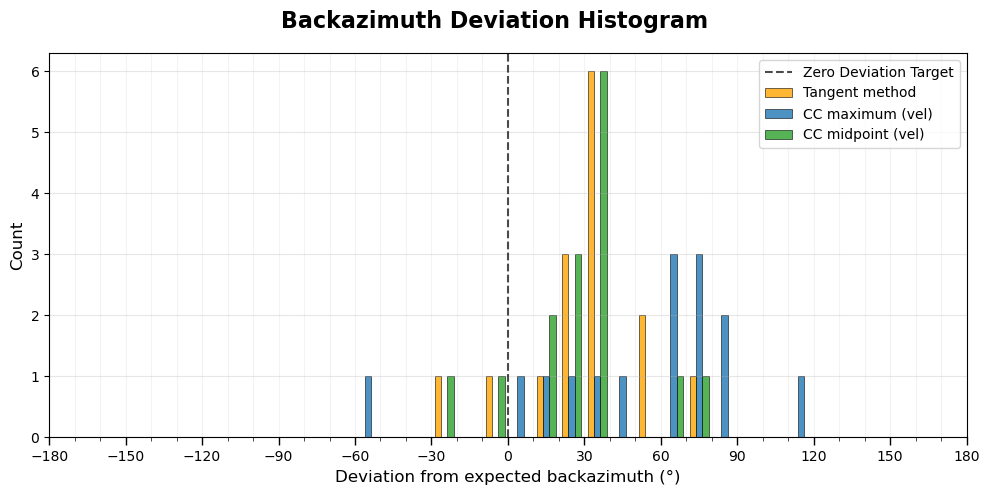

In [12]:
# Function to calculate circular deviation (wrapped to [-180, 180])
def circular_deviation(estimated, theoretical):
    """Calculate deviation between estimated and theoretical, wrapped to [-180, 180] degrees."""
    diff = estimated - theoretical
    # Wrap to [-180, 180]
    diff = np.where(diff > 180, diff - 360, diff)
    diff = np.where(diff < -180, diff + 360, diff)
    return diff

# Calculate deviations for all methods
deviations = {}

# Velocity methods
valid_vel = df_baz.dropna(subset=['baz_vel_theoretical'])
if len(valid_vel) > 0:
    theoretical_vel = valid_vel['baz_vel_theoretical'].values
    
    # Velocity Max
    valid_vel_max = valid_vel.dropna(subset=['baz_vel_max_peak'])
    if len(valid_vel_max) > 0:
        deviations['Vel Max'] = circular_deviation(
            valid_vel_max['baz_vel_max_peak'].values,
            valid_vel_max['baz_vel_theoretical'].values
        )
    
    # Velocity Mid
    valid_vel_mid = valid_vel.dropna(subset=['baz_vel_mid_peak'])
    if len(valid_vel_mid) > 0:
        deviations['Vel Mid'] = circular_deviation(
            valid_vel_mid['baz_vel_mid_peak'].values,
            valid_vel_mid['baz_vel_theoretical'].values
        )
    
    # Tangent Velocity Max
    valid_tan_vel_max = valid_vel.dropna(subset=['tangent_vel_max'])
    if len(valid_tan_vel_max) > 0:
        deviations['Tangent Vel Max'] = circular_deviation(
            valid_tan_vel_max['tangent_vel_max'].values,
            valid_tan_vel_max['baz_vel_theoretical'].values
        )
    
    # Tangent Velocity Mid
    valid_tan_vel_mid = valid_vel.dropna(subset=['tangent_vel_mid'])
    if len(valid_tan_vel_mid) > 0:
        deviations['Tangent Vel Mid'] = circular_deviation(
            valid_tan_vel_mid['tangent_vel_mid'].values,
            valid_tan_vel_mid['baz_vel_theoretical'].values
        )

# Acceleration methods
valid_acc = df_baz.dropna(subset=['baz_acc_theoretical'])
if len(valid_acc) > 0:
    theoretical_acc = valid_acc['baz_acc_theoretical'].values
    
    # Acceleration Max
    valid_acc_max = valid_acc.dropna(subset=['baz_acc_max_peak'])
    if len(valid_acc_max) > 0:
        deviations['Acc Max'] = circular_deviation(
            valid_acc_max['baz_acc_max_peak'].values,
            valid_acc_max['baz_acc_theoretical'].values
        )
    
    # Acceleration Mid
    valid_acc_mid = valid_acc.dropna(subset=['baz_acc_mid_peak'])
    if len(valid_acc_mid) > 0:
        deviations['Acc Mid'] = circular_deviation(
            valid_acc_mid['baz_acc_mid_peak'].values,
            valid_acc_mid['baz_acc_theoretical'].values
        )
    
    # Tangent Acceleration Max
    valid_tan_acc_max = valid_acc.dropna(subset=['tangent_acc_max'])
    if len(valid_tan_acc_max) > 0:
        deviations['Tangent Acc Max'] = circular_deviation(
            valid_tan_acc_max['tangent_acc_max'].values,
            valid_tan_acc_max['baz_acc_theoretical'].values
        )
    
    # Tangent Acceleration Mid
    valid_tan_acc_mid = valid_acc.dropna(subset=['tangent_acc_mid'])
    if len(valid_tan_acc_mid) > 0:
        deviations['Tangent Acc Mid'] = circular_deviation(
            valid_tan_acc_mid['tangent_acc_mid'].values,
            valid_tan_acc_mid['baz_acc_theoretical'].values
        )

# Single histogram: Tangent Vel Max + Max/Mid methods for one family
# Choose which family to compare ('velocity' or 'acceleration')
family = 'velocity'  # options: 'velocity', 'acceleration'

fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Backazimuth Deviation Histogram', fontsize=16, fontweight='bold')

# 10° bins from -180 to 180
bin_size = 10
bins = np.arange(-180, 180 + bin_size, bin_size)
bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

# Colors for methods
colors = {
    'Vel Max': 'tab:blue',
    'Vel Mid': 'tab:green',
    'Acc Max': 'tab:purple',
    'Acc Mid': 'tab:red',
    'Tangent Vel Max': 'orange',
}

# Pretty labels for legend
labels = {
    'Vel Max': 'CC maximum (vel)',
    'Vel Mid': 'CC midpoint (vel)',
    'Acc Max': 'CC maximum (acc)',
    'Acc Mid': 'CC midpoint (acc)',
    'Tangent Vel Max': 'Tangent method',
}

# Collect methods to plot
methods_to_plot = []
if 'Tangent Vel Max' in deviations:
    methods_to_plot.append('Tangent Vel Max')

# Add max and midpoint for chosen family
if family == 'velocity':
    methods = ['Vel Max', 'Vel Mid']
    title_suffix = 'Velocity Max/Mid and Tangent Vel Max'
elif family == 'acceleration':
    methods = ['Acc Max', 'Acc Mid']
    title_suffix = 'Acceleration Max/Mid and Tangent Vel Max'
else:
    methods = []
    title_suffix = ''

for method in methods:
    if method in deviations:
        methods_to_plot.append(method)

# Calculate number of methods and bar width
n_methods = len(methods_to_plot)
bar_width = bin_width / (n_methods + 1)  # Make bars thinner with spacing

# Plot each method as bars shifted next to each other
for i, method in enumerate(methods_to_plot):
    if method in deviations:
        # Calculate histogram counts
        counts, _ = np.histogram(deviations[method], bins=bins)
        
        # Offset position for this method
        offset = (i - (n_methods - 1) / 2) * bar_width
        x_pos = bin_centers + offset
        
        ax.bar(
            x_pos,
            counts,
            width=bar_width * 1.,  # Make bars thinner (80% of allocated width)
            alpha=0.8,
            label=labels.get(method, method),
            color=colors.get(method, 'gray'),
            edgecolor='black',
            linewidth=0.5,
        )

# Reference line at zero deviation
ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Zero Deviation Target')

ax.set_xlabel('Deviation from expected backazimuth (°)', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
# ax.set_title(f'Deviations: {title_suffix}', fontsize=13, fontweight='bold')
ax.set_xlim(-180, 180)

# Add minor ticks for x-axis
ax.set_xticks(np.arange(-180, 181, 10), minor=True)
ax.set_xticks(np.arange(-180, 181, 30), minor=False)  # Major ticks every 30 degrees
ax.tick_params(axis='x', which='minor', length=3, width=0.5)
ax.tick_params(axis='x', which='major', length=6, width=1)

ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y', which='major')
ax.grid(True, alpha=0.15, axis='x', which='both', linestyle='-')

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_deviation_histogram.png", bbox_inches='tight', dpi=150)


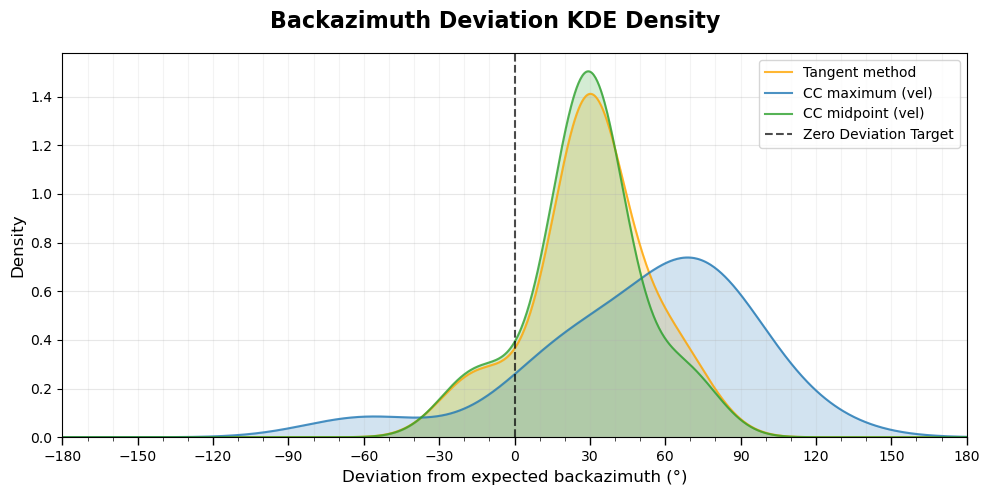

In [13]:
# KDE Density Plot: Same plot but with KDE density functions instead of histograms
# Choose which family to compare ('velocity' or 'acceleration')
family = 'velocity'  # options: 'velocity', 'acceleration'

fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('Backazimuth Deviation KDE Density', fontsize=16, fontweight='bold')

# Create fine grid for KDE evaluation
x_kde = np.linspace(-180, 180, 1000)

# Colors for methods
colors = {
    'Vel Max': 'tab:blue',
    'Vel Mid': 'tab:green',
    'Acc Max': 'tab:purple',
    'Acc Mid': 'tab:red',
    'Tangent Vel Max': 'orange',
}

# Pretty labels for legend
labels = {
    'Vel Max': 'CC maximum (vel)',
    'Vel Mid': 'CC midpoint (vel)',
    'Acc Max': 'CC maximum (acc)',
    'Acc Mid': 'CC midpoint (acc)',
    'Tangent Vel Max': 'Tangent method',
}

# Collect methods to plot
methods_to_plot = []
if 'Tangent Vel Max' in deviations:
    methods_to_plot.append('Tangent Vel Max')

# Add max and midpoint for chosen family
if family == 'velocity':
    methods = ['Vel Max', 'Vel Mid']
    title_suffix = 'Velocity Max/Mid and Tangent Vel Max'
elif family == 'acceleration':
    methods = ['Acc Max', 'Acc Mid']
    title_suffix = 'Acceleration Max/Mid and Tangent Vel Max'
else:
    methods = []
    title_suffix = ''

for method in methods:
    if method in deviations:
        methods_to_plot.append(method)

# Plot KDE density for each method
for method in methods_to_plot:
    if method in deviations and len(deviations[method]) > 1:
        data = deviations[method]
        
        # Calculate KDE (returns probability density function)
        kde = stats.gaussian_kde(data)
        kde_values = kde(x_kde)
        
        # Scale to match histogram counts: PDF * n_samples * bin_width
        # Use histogram bin width (10°) for proper scaling
        bin_width_hist = 5.0
        kde_values = kde_values * len(data) * bin_width_hist
        
        ax.plot(
            x_kde,
            kde_values,
            linewidth=1.5,
            alpha=0.8,
            label=labels.get(method, method),
            color=colors.get(method, 'gray'),
        )
        
        # Fill under the curve with transparency
        ax.fill_between(
            x_kde,
            kde_values,
            alpha=0.2,
            color=colors.get(method, 'gray'),
        )

# Reference line at zero deviation
ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Zero Deviation Target')

ax.set_xlabel('Deviation from expected backazimuth (°)', fontsize=12)
ax.set_ylabel('Density', fontsize=12)
ax.set_xlim(-180, 180)
ax.set_ylim(bottom=0)

# Add minor ticks for x-axis
ax.set_xticks(np.arange(-180, 181, 10), minor=True)
ax.set_xticks(np.arange(-180, 181, 30), minor=False)  # Major ticks every 30 degrees
ax.tick_params(axis='x', which='minor', length=3, width=0.5)
ax.tick_params(axis='x', which='major', length=6, width=1)

ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y', which='major')
ax.grid(True, alpha=0.15, axis='x', which='both', linestyle='-')

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_deviation_kde.png", bbox_inches='tight', dpi=150)

/tmp/ipykernel_162032/2198177959.py:286: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_yticklabels([f'{int(d)}°' for d in ax3.get_yticks()], fontsize=12)
/tmp/ipykernel_162032/2198177959.py:316: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


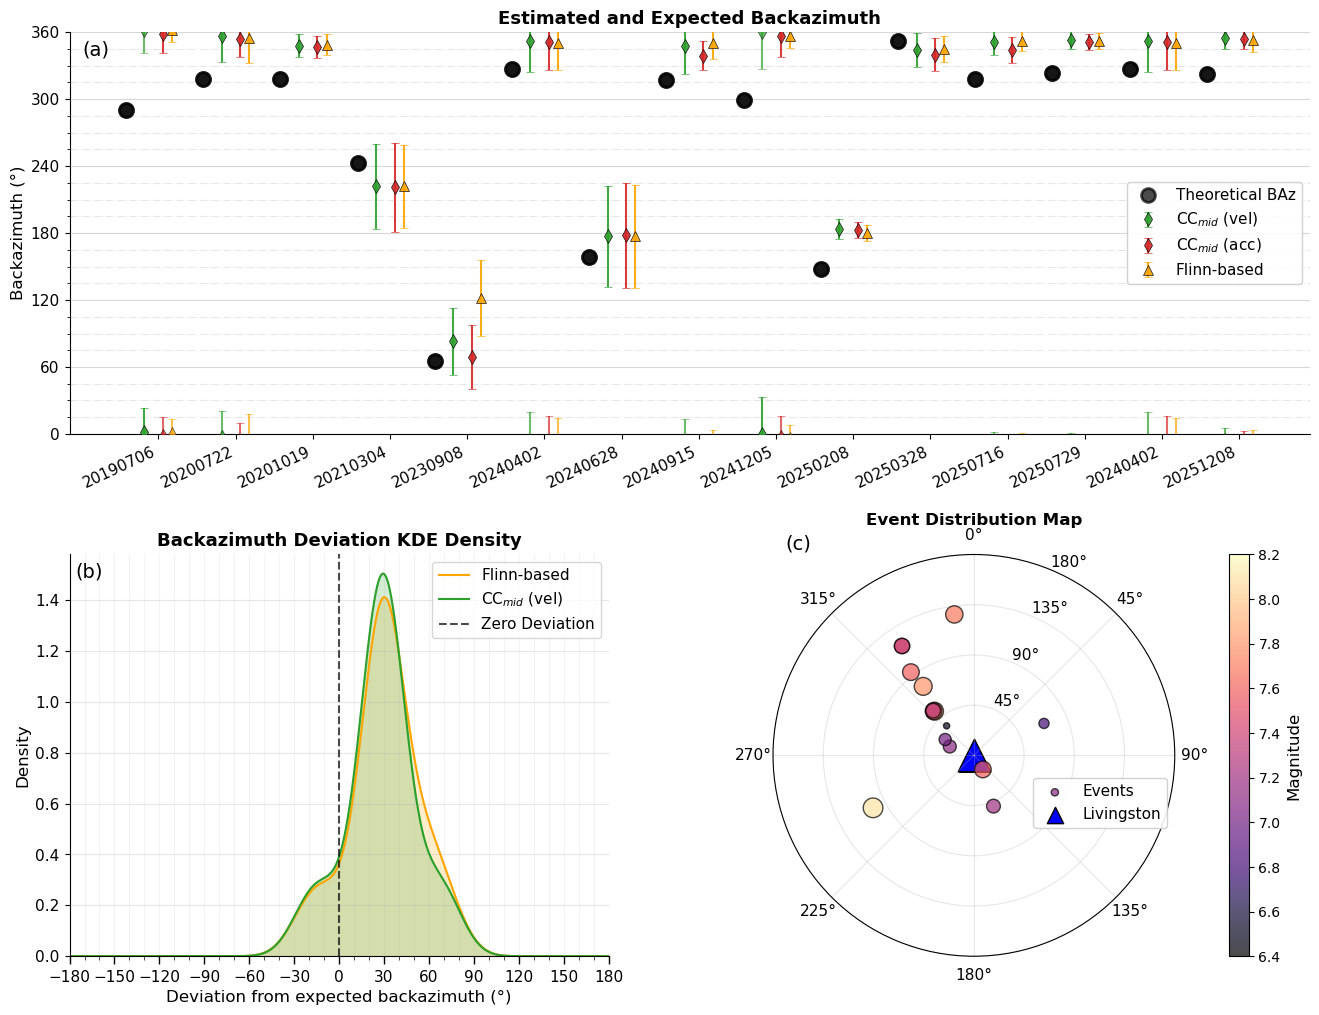

In [20]:
# Combined plot: Backazimuth comparison, KDE density, and polar map
from obspy.geodetics import gps2dist_azimuth, kilometers2degrees
from obspy.taup import TauPyModel
import matplotlib.patches as mpatches

# Station coordinates (LIV)
station_lat = 30.56287
station_lon = -90.77422

# Create figure with subplots: 2 rows, 2 columns
# Top row spans 2 columns, bottom row has 2 columns
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, hspace=0.3, wspace=0.3, 
                      height_ratios=[1, 1], width_ratios=[1, 1])

# ===== SUBPLOT 1: Backazimuth Comparison (top row, spans 2 columns) =====
ax1 = fig.add_subplot(gs[0, :])

# Get events that have theoretical values (use velocity theoretical as base)
valid_base = df_baz.dropna(subset=['baz_vel_theoretical'])
x_base = np.arange(len(valid_base))
theoretical = valid_base['baz_vel_theoretical'].values
width = 0.12  # Shift width for positioning multiple methods

# Plot theoretical values (leftmost position) - twice
x_theoretical = x_base - width * 3.5
ax1.errorbar(x_theoretical, theoretical, fmt='o', color='black', markersize=10, 
            label='Theoretical BAz', linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)
ax1.errorbar(x_theoretical, theoretical % 360, fmt='o', color='black', markersize=10, 
            linewidth=2.5, zorder=10, markeredgewidth=2, alpha=0.7)

# Velocity Max method
# valid_vel_max = valid_base.dropna(subset=['baz_vel_max_peak', 'baz_vel_max_uncertainty'])
# if len(valid_vel_max) > 0:
#     x_vel_max = x_base[valid_base.index.isin(valid_vel_max.index)] - width * 2.5
#     estimated = valid_vel_max['baz_vel_max_peak'].values
#     uncertainty = valid_vel_max['baz_vel_max_uncertainty'].values
#     ax1.errorbar(x_vel_max, estimated, yerr=uncertainty, fmt='s', color='tab:blue', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.9,
#                 label='CC$_{max}$ (vel)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
#     ax1.errorbar(x_vel_max, estimated + 360, yerr=uncertainty, fmt='s', color='tab:blue', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.7,
#                 linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
#     ax1.errorbar(x_vel_max, estimated - 360, yerr=uncertainty, fmt='s', color='tab:blue', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.7,
#                 linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Velocity Mid method
valid_vel_mid = valid_base.dropna(subset=['baz_vel_mid_peak', 'baz_vel_mid_uncertainty'])
if len(valid_vel_mid) > 0:
    x_vel_mid = x_base[valid_base.index.isin(valid_vel_mid.index)] - width * 1.5
    estimated = valid_vel_mid['baz_vel_mid_peak'].values
    uncertainty = valid_vel_mid['baz_vel_mid_uncertainty'].values
    ax1.errorbar(x_vel_mid, estimated, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC$_{mid}$ (vel)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_vel_mid, estimated + 360, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_vel_mid, estimated - 360, yerr=uncertainty, fmt='d', color='tab:green', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Acceleration Max method
# valid_acc_max = valid_base.dropna(subset=['baz_acc_max_peak', 'baz_acc_max_uncertainty'])
# if len(valid_acc_max) > 0:
#     x_acc_max = x_base[valid_base.index.isin(valid_acc_max.index)] - width * 0.5
#     estimated = valid_acc_max['baz_acc_max_peak'].values
#     uncertainty = valid_acc_max['baz_acc_max_uncertainty'].values
#     ax1.errorbar(x_acc_max, estimated, yerr=uncertainty, fmt='s', color='tab:purple', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.9,
#                 label='CC$_{max}$ (acc)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
#     ax1.errorbar(x_acc_max, estimated + 360, yerr=uncertainty, fmt='s', color='tab:purple', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.7,
#                 linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
#     ax1.errorbar(x_acc_max, estimated - 360, yerr=uncertainty, fmt='s', color='tab:purple', 
#                 markersize=7, capsize=3, capthick=1.5, alpha=0.7,
#                 linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Acceleration Mid method
valid_acc_mid = valid_base.dropna(subset=['baz_acc_mid_peak', 'baz_acc_mid_uncertainty'])
if len(valid_acc_mid) > 0:
    x_acc_mid = x_base[valid_base.index.isin(valid_acc_mid.index)] + width * 0.5
    estimated = valid_acc_mid['baz_acc_mid_peak'].values
    uncertainty = valid_acc_mid['baz_acc_mid_uncertainty'].values
    ax1.errorbar(x_acc_mid, estimated, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='CC$_{mid}$ (acc)', linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_acc_mid, estimated + 360, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_acc_mid, estimated - 360, yerr=uncertainty, fmt='d', color='tab:red', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=5, markeredgecolor='k', markeredgewidth=0.5)

# Tangent Velocity Max
valid_tan_vel_max = valid_base.dropna(subset=['tangent_vel_max', 'tangent_vel_max_uncertainty'])
if len(valid_tan_vel_max) > 0:
    x_tan_vel_max = x_base[valid_base.index.isin(valid_tan_vel_max.index)] + width * 1.5
    estimated = valid_tan_vel_max['tangent_vel_max'].values
    if 'tangent_vel_max_uncertainty' in valid_tan_vel_max.columns:
        uncertainty = valid_tan_vel_max['tangent_vel_max_uncertainty'].values
    else:
        print(f"No uncertainty for {valid_tan_vel_max.index.values[0]}")
        uncertainty = None
    ax1.errorbar(x_tan_vel_max, estimated, yerr=uncertainty, fmt='^', color='orange', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.9,
                label='Flinn-based', linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_tan_vel_max, estimated + 360, yerr=uncertainty, fmt='^', color='orange', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)
    ax1.errorbar(x_tan_vel_max, estimated - 360, yerr=uncertainty, fmt='^', color='orange', 
                markersize=7, capsize=3, capthick=1.5, alpha=0.7,
                linewidth=1.5, zorder=4, markeredgecolor='k', markeredgewidth=0.5)

ax1.set_yticks(np.arange(0, 420, 60))
ax1.tick_params(axis='both', which='major', labelsize=10)
ax1.set_ylabel('Backazimuth (°)', fontsize=12)
ax1.set_title('Estimated and Expected Backazimuth', fontsize=13, fontweight='bold')
ax1.set_xticks(x_base)
ax1.set_xticklabels(valid_base['event'].str.replace('event_', '').values, rotation=25, ha='right', fontsize=11)
ax1.set_ylim(0, 360)
ax1.legend(fontsize=11, loc=7, ncol=1, framealpha=0.9)
ax1.get_yaxis().set_minor_locator(mpl.ticker.AutoMinorLocator())
ax1.grid(which='major', alpha=0.5, axis='y', zorder=0)
ax1.grid(which='minor', alpha=0.3, axis='y', zorder=0, ls="-.")

# Add subplot label (a)
ax1.text(0.01, 0.98, '(a)', transform=ax1.transAxes, fontsize=14,
         verticalalignment='top')

# ===== SUBPLOT 2: KDE Density Plot (bottom left) =====
ax2 = fig.add_subplot(gs[1, 0])

# Choose which family to compare ('velocity' or 'acceleration')
family = 'velocity'  # options: 'velocity', 'acceleration'

# Create fine grid for KDE evaluation
x_kde = np.linspace(-180, 180, 1000)

# Colors for methods
colors_kde = {
    'Vel Max': 'tab:blue',
    'Vel Mid': 'tab:green',
    'Acc Max': 'tab:purple',
    'Acc Mid': 'tab:red',
    'Tangent Vel Max': 'orange',
}

# Pretty labels for legend
labels_kde = {
    'Vel Max': r'CC$_{max}$ (vel)',
    'Vel Mid': r'CC$_{mid}$ (vel)',
    'Acc Max': r'CC$_{max}$ (acc)',
    'Acc Mid': r'CC$_{mid}$ (acc)',
    'Tangent Vel Max': 'Flinn-based',
}

# Collect methods to plot
methods_to_plot = []
if 'Tangent Vel Max' in deviations:
    methods_to_plot.append('Tangent Vel Max')

# Add max and midpoint for chosen family
if family == 'velocity':
    methods = ['Vel Mid'] # ['Vel Max', 'Vel Mid']
elif family == 'acceleration':
    methods = ['Acc Mid'] # ['Acc Max', 'Acc Mid']
else:
    methods = []

for method in methods:
    if method in deviations:
        methods_to_plot.append(method)

# Plot KDE density for each method
for method in methods_to_plot:
    if method in deviations and len(deviations[method]) > 1:
        data = deviations[method]
        
        # Calculate KDE (returns probability density function)
        kde = stats.gaussian_kde(data)
        kde_values = kde(x_kde)
        
        # Scale to match histogram counts: PDF * n_samples * bin_width
        bin_width_hist = 5.0
        kde_values = kde_values * len(data) * bin_width_hist
        
        ax2.plot(
            x_kde,
            kde_values,
            linewidth=1.5,
            alpha=1,
            label=labels_kde.get(method, method),
            color=colors_kde.get(method, 'gray'),
        )
        
        # Fill under the curve with transparency
        ax2.fill_between(
            x_kde,
            kde_values,
            alpha=0.2,
            color=colors_kde.get(method, 'gray'),
        )

# Reference line at zero deviation
ax2.axvline(x=0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Zero Deviation')

ax2.set_xlabel('Deviation from expected backazimuth (°)', fontsize=12)
ax2.set_ylabel('Density', fontsize=12)
ax2.set_title('Backazimuth Deviation KDE Density', fontsize=13, fontweight='bold')
ax2.set_xlim(-180, 180)
ax2.set_ylim(bottom=0)

# Add minor ticks for x-axis
ax2.set_xticks(np.arange(-180, 181, 10), minor=True)
ax2.set_xticks(np.arange(-180, 181, 30), minor=False)
ax2.tick_params(axis='x', which='minor', length=3, width=0.5)
ax2.tick_params(axis='x', which='major', length=6, width=1)

ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3, axis='y', which='major')
ax2.grid(True, alpha=0.15, axis='x', which='both', linestyle='-')

# Add subplot label (b)
ax2.text(0.01, 0.98, '(b)', transform=ax2.transAxes, fontsize=14,
         verticalalignment='top')

# ===== SUBPLOT 3: Polar Map (bottom right) =====
ax3 = fig.add_subplot(gs[1, 1], projection='polar')

# make a discrete color map
cmap = plt.magma()

# Get event data with valid theoretical backazimuth and distance
valid_events = df_baz.dropna(subset=['baz_vel_theoretical', 'epicentral_distance_km', 'magnitude'])

epicentral_distance_degrees = valid_events['epicentral_distance_km'].values /6371 * 180 / np.pi

if len(valid_events) > 0:

    # Set radial limits (distance in km) - need to set early for continent plotting
    max_distance = 180
    ax3.set_ylim(0, max_distance)
    
    # Set theta zero location to North (0°) and clockwise direction
    ax3.set_theta_zero_location('N')
    ax3.set_theta_direction(-1)
        
    # Convert backazimuth to radians (for polar plot)
    baz_rad = np.deg2rad(valid_events['baz_vel_theoretical'].values)
    distances = epicentral_distance_degrees
    magnitudes = valid_events['magnitude'].values
    
    # Scale marker size by magnitude (min size 20, max size 200)
    min_mag = magnitudes.min()
    max_mag = magnitudes.max()
    if max_mag > min_mag:
        marker_sizes = 20 + (magnitudes - min_mag) / (max_mag - min_mag) * 180
    else:
        marker_sizes = np.full_like(magnitudes, 100)
    
    # Create discrete colorbar levels (0.2 steps)
    mag_min_rounded = np.floor(min_mag * 5) / 5  # Round down to nearest 0.2
    mag_max_rounded = np.ceil(max_mag * 5) / 5    # Round up to nearest 0.2
    mag_levels = np.arange(mag_min_rounded, mag_max_rounded + 0.2, 0.2)
    
    # Plot events with discrete colors
    scatter = ax3.scatter(baz_rad, distances, c=magnitudes, s=marker_sizes, 
                         cmap=cmap, alpha=0.7, edgecolors='black', linewidths=1,
                         zorder=5, label='Events', vmin=mag_levels[0], vmax=mag_levels[-1])
    
    # Add discrete colorbar
    cbar = plt.colorbar(scatter, ax=ax3, pad=0.1, ticks=mag_levels)
    cbar.set_label('Magnitude', fontsize=12)
    cbar.set_ticklabels([f'{m:.1f}' for m in mag_levels])
    
    # Plot station at center (distance = 0)
    ax3.scatter(0, 0, marker='^', s=550, color='blue', 
               edgecolors='black', linewidths=1, zorder=1, label='Livingston')
    
    # Customize radial axis
    ax3.set_title('Event Distribution Map', fontsize=12, fontweight='bold', pad=2)
    
    # Set radial axis labels with unit degrees
    ax3.set_yticklabels([f'{int(d)}°' for d in ax3.get_yticks()], fontsize=12)

    # Add grid
    ax3.grid(True, alpha=0.3)
    
    # Add legend
    ax3.legend(loc='lower right', fontsize=11, framealpha=0.9, markerscale=0.5, bbox_to_anchor=(1.0, 0.3))
    
    # Add distance circles
    ax3.set_yticks(np.linspace(0, max_distance, 5))

    ylbls = [f'{int(d)}°' for d in np.linspace(0, max_distance, 5)]
    ylbls[0] = ''
    ax3.set_yticklabels(ylbls, fontsize=11)
    
    
    # Add subplot label (c)
    ax3.text(0.03, 1.05, '(c)', transform=ax3.transAxes, fontsize=14,
             verticalalignment='top', zorder=15)

# remove top and right spines
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

ax1.tick_params(axis='both', which='major', labelsize=11)
ax2.tick_params(axis='both', which='major', labelsize=11)
ax3.tick_params(axis='both', which='major', labelsize=11)

plt.tight_layout()
plt.show()

if save_figures:
    fig.savefig(f"{path_to_figures}/backazimuth_results_summary.png", bbox_inches='tight', dpi=150)